In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','reject','pt1','pt2','y1','y2','phi1','phi2','nef','evid']
observabless1 = ['pts','bs','ws','rejects','pt1s','pt2s','y1s','y2s','phi1s','phi2s','nefs','evids']

In [4]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_tow104.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [5]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

In [6]:
df_allreco = applyCut(df_allreco, 'not (pts>25 and w>4e-9)')

Process PYTHIA6+GEANT

In [7]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [8]:
df_match.shape[0]

43630

In [9]:
w_array = np.unique(df_match['w'])

In [10]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)] ]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [11]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

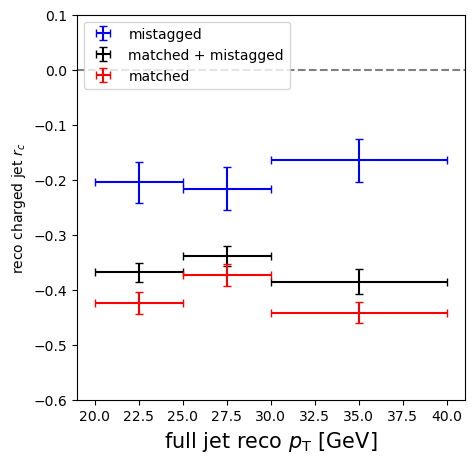

In [12]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [13]:
rc_allfake_bs_vs_pts_array

[-0.2646726023043114,
 -0.20451454239700304,
 -0.21599487226637404,
 -0.16502471835588342,
 -0.2961258984602076]

In [14]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [15]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [16]:
b_fake_array

[array([0.6323363, 0.3676637]),
 array([0.60225727, 0.39774273]),
 array([0.60799744, 0.39200256]),
 array([0.58251236, 0.41748764]),
 array([0.64806295, 0.35193705])]

In [17]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [18]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

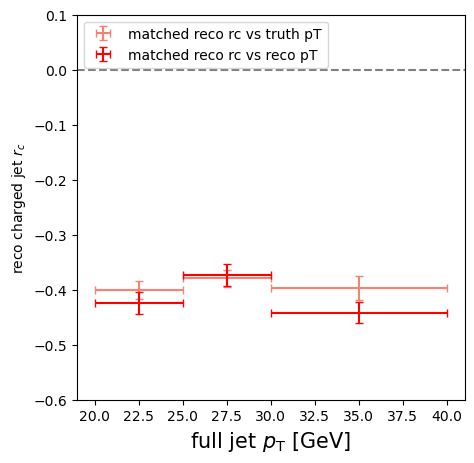

In [19]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [20]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.71145707 0.28854293]
[0.71220484 0.28779516]
[0.68643405 0.31356595]
[0.72071307 0.27928693]
[0.67761184 0.32238816]


In [21]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_1000051/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [22]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.2994526 , 0.25441432, 0.22167776, 0.20347983, 0.24020857])

Process data

In [23]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9 and bs!=0')

In [24]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [25]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [26]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [27]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [28]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [29]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[239709.57946873 121393.18210288]
[489.60144962 348.41524379]
1
[72379. 38554.]
[55381.52658473 27328.52912197]
[235.33279964 165.31342693]
2
[16450.  8688.]
[13061.91260844  6503.55173564]
[114.28872477  80.6446014 ]
3
[4758. 2573.]
[3889.06011158 1950.22924103]
[62.36232927 44.1613999 ]
4
[334. 153.]
[258.18857553 111.82984951]
[16.06824743 10.57496333]


In [30]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [31]:
reweight_array

[array([0.93305208, 1.16507274]),
 array([0.94015983, 1.14808609]),
 array([0.97256311, 1.06006269]),
 array([0.924107  , 1.19584546]),
 array([1.0297521 , 0.93746552])]

Reweight PYTHIA6+GEANT

In [32]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 61.340801125675725
anomaly reco pT: 60.198812489195895
anomaly reco pT: 61.19832698362156


/tmp/ipykernel_1000051/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [33]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [34]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [35]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

In [36]:
rc_match_bs_vs_pts_array

[-0.3276529840172282,
 -0.3391727550303146,
 -0.3352008803605854,
 -0.33203199113264276]

Plot result

(-0.6, 0.1)

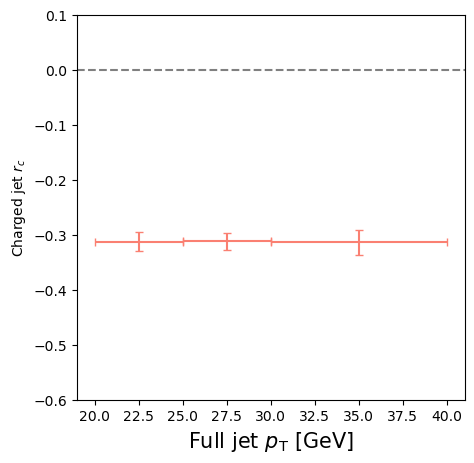

In [37]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:], capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [38]:
rc_match_bs_vs_pt_array

[-0.3210228436108087,
 -0.31277254848053226,
 -0.3122317907611789,
 -0.31378969220589203]

In [39]:
rc_err_match_bs_vs_pt_array

[0.01762627766073011,
 0.017103057902613676,
 0.016237920376146207,
 0.023212088902109608]